# Vehicle Type Classification — ML Mini Project (Classification Part)
**Author:** Shubham Singh, M.Tech CSE, IIIT Bangalore
**Course:** Machine Learning (Semester 1), Course Project I

**Task:** Predict `vehicle_class` (3 classes: 0, 1, 2) from 20 numeric technical specifications of a vehicle.

**Notebook structure** (follows the project statement):
1. Problem & dataset
2. Exploratory Data Analysis (EDA)
3. Preprocessing (with justification)
4. Model experimentation using every classifier taught in the course: Bayes classifier (Gaussian, plus its LDA special case), Naive Bayes, Logistic Regression, Decision Tree, Random Forest, XGBoost, CatBoost, plus ensembles of these
5. Model comparison table, results & discussion
6. Best model and final Kaggle submission

**Reproducibility:** one global `SEED = 42` is passed to every CV splitter, search and model (including the `saga` solver of Logistic Regression), so re-running the notebook gives identical results.

In [1]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 50)
sns.set_theme(style='whitegrid', context='notebook')
SEED = 42
np.random.seed(SEED)

# Works locally and on Kaggle (finds the csv files wherever they are)
def find_dir():
    for root in ['/kaggle/input', '.', './data', '../data', '/home/claude/data']:
        if os.path.isdir(root):
            for dp, _, fs in os.walk(root):
                if 'vehicle_test.csv' in fs:
                    return dp
    raise FileNotFoundError('vehicle_test.csv not found')
DATA_DIR = find_dir()
OUT_DIR = 'submissions'; os.makedirs(OUT_DIR, exist_ok=True)

train = pd.read_csv(f'{DATA_DIR}/vehicle_train_10000.csv')
test  = pd.read_csv(f'{DATA_DIR}/vehicle_test.csv')
sample_sub = pd.read_csv(f'{DATA_DIR}/vehicle_sample_submission.csv')
TARGET, ID = 'vehicle_class', 'vehicle_id'
FEATURES = [c for c in train.columns if c not in (TARGET, ID)]
print('train', train.shape, '| test', test.shape, '| sample submission', sample_sub.shape)
print(len(FEATURES), 'features')
train.head()

train (10000, 22) | test (2500, 21) | sample submission (2500, 2)
20 features


,vehicle_id,engine_displacement_l,horsepower_hp,vehicle_weight_kg,wheelbase_mm,vehicle_length_mm,vehicle_width_mm,vehicle_height_mm,fuel_tank_capacity_l,city_fuel_efficiency_kmpl,highway_fuel_efficiency_kmpl,engine_cylinders,torque_nm,ground_clearance_mm,turning_radius_m,cargo_capacity_l,acceleration_0_100_kmh_s,braking_distance_m,tire_width_mm,drag_coefficient,battery_capacity_kwh,vehicle_class
0,1,2.56,290.0,1532.0,2737.0,4538.0,1814.0,1544.0,65.0,9.69,13.86,7.0,438.0,197.0,6.05,656.0,5.87,43.0,267.0,0.34,79.0,2
1,2,2.70,350.0,1529.0,2726.0,4473.0,1848.0,1636.0,62.0,10.35,14.32,7.0,441.0,251.0,5.30,513.0,6.48,41.0,247.0,0.28,76.0,2
2,3,2.50,335.0,1100.0,2504.0,3900.0,1650.0,1251.0,35.0,13.70,17.60,7.0,471.0,110.0,5.58,150.0,3.90,29.0,261.0,0.23,89.0,2
3,4,3.00,345.0,2069.0,3053.0,5134.0,2036.0,1572.0,81.0,10.72,16.45,7.0,478.0,168.0,6.36,626.0,6.20,51.0,283.0,0.37,60.0,1
4,5,1.59,155.0,1574.0,2791.0,4678.0,1804.0,1492.0,60.0,13.55,16.71,4.0,235.0,179.0,5.43,447.0,10.15,47.0,201.0,0.34,43.0,1


## 1. Problem and Dataset

* **Type:** supervised, multi-class (3-way) classification.
* **Train:** 10,000 rows × 20 numeric features + `vehicle_id` + target `vehicle_class`.
* **Test:** 2,500 rows (ids 10001–12500). Submission = `vehicle_id, vehicle_class`.
* **Features:** engine (displacement, hp, torque, cylinders, battery capacity), body dimensions (length, width, height, wheelbase, ground clearance, weight), practicality (cargo, fuel tank), performance/efficiency (0–100 time, braking distance, city/highway km/l, drag coefficient, tyre width, turning radius).
* **Metric:** classes are balanced, so we report **accuracy** (the usual Kaggle metric for this kind of task) as the primary score and **macro-F1** as a secondary check. On balanced data the two are almost identical.

In [2]:
print(train.dtypes.value_counts()); print()
print('Missing values  train:', train.isna().sum().sum(), '| test:', test.isna().sum().sum())
display(train[FEATURES].describe().T.round(2))

float64    20
int64       2
Name: count, dtype: int64

Missing values  train: 0 | test: 0


,count,mean,std,min,25%,50%,75%,max
engine_displacement_l,10000.0,2.43,0.61,0.90,2.00,2.43,2.85,4.44
horsepower_hp,10000.0,296.50,95.56,90.00,226.00,294.00,364.00,550.00
vehicle_weight_kg,10000.0,1636.40,306.18,1100.00,1409.00,1604.00,1852.00,2600.00
wheelbase_mm,10000.0,2778.06,172.35,2400.00,2651.00,2756.00,2906.00,3300.00
vehicle_length_mm,10000.0,4660.04,366.06,3900.00,4387.75,4622.00,4937.00,5400.00
vehicle_width_mm,10000.0,1836.67,117.74,1650.00,1744.00,1824.00,1928.00,2050.00
vehicle_height_mm,10000.0,1528.94,145.98,1250.00,1423.00,1530.00,1634.00,2050.00
fuel_tank_capacity_l,10000.0,61.10,14.51,35.00,50.00,60.00,72.00,90.00
city_fuel_efficiency_kmpl,10000.0,11.61,2.57,7.00,9.75,11.56,13.36,20.87
highway_fuel_efficiency_kmpl,10000.0,15.85,2.50,9.00,14.16,15.83,17.55,24.07


## 2. Exploratory Data Analysis

### 2.1 Target distribution

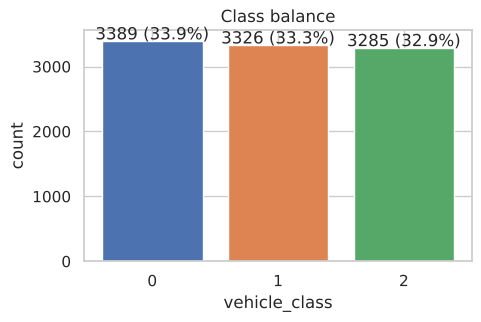

In [3]:
vc = train[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5,3))
ax.bar(vc.index.astype(str), vc.values, color=['#4C72B0','#DD8452','#55A868'])
for i, v in enumerate(vc.values): ax.text(i, v+30, f'{v} ({v/len(train):.1%})', ha='center')
ax.set_xlabel('vehicle_class'); ax.set_ylabel('count'); ax.set_title('Class balance'); plt.show()

**Observation:** the three classes are almost perfectly balanced (~33% each), so we need no resampling or class weights, and accuracy is a fair metric.

### 2.2 Duplicate rows (an important finding)

In [4]:
dup_mask = train.duplicated(FEATURES, keep='first')
grp = train[train.duplicated(FEATURES, keep=False)].groupby(FEATURES)[TARGET].agg(['nunique','size'])
print('Exact duplicate feature rows      :', dup_mask.sum())
print('Group sizes                        :', grp['size'].value_counts().to_dict())
print('Duplicate groups with label conflict:', (grp['nunique']>1).sum())
print('vehicle_id range of the copies     :', train.loc[dup_mask, ID].min(), '-', train.loc[dup_mask, ID].max())
print('Test rows that exactly exist in train:', len(test.merge(train[FEATURES].drop_duplicates(), on=FEATURES)))
print('Duplicate rows inside test        :', test.duplicated(FEATURES).sum())

Exact duplicate feature rows      : 2500
Group sizes                        : {2: 2500}
Duplicate groups with label conflict: 0
vehicle_id range of the copies     : 7501 - 10000


Test rows that exactly exist in train: 0
Duplicate rows inside test        : 0


**Observation:** rows with ids **7501–10000 (2,500 rows, 25% of train) are exact copies** of earlier rows, with identical labels. The test set contains none of them.
If we keep them, a copy can land in the training fold while its twin is in the validation fold, so cross-validation **leaks** and becomes over-optimistic. Flexible memorising models (trees, forests, boosting) gain the most from that leak. This is demonstrated quantitatively in Section 3.

### 2.3 Feature distributions by class

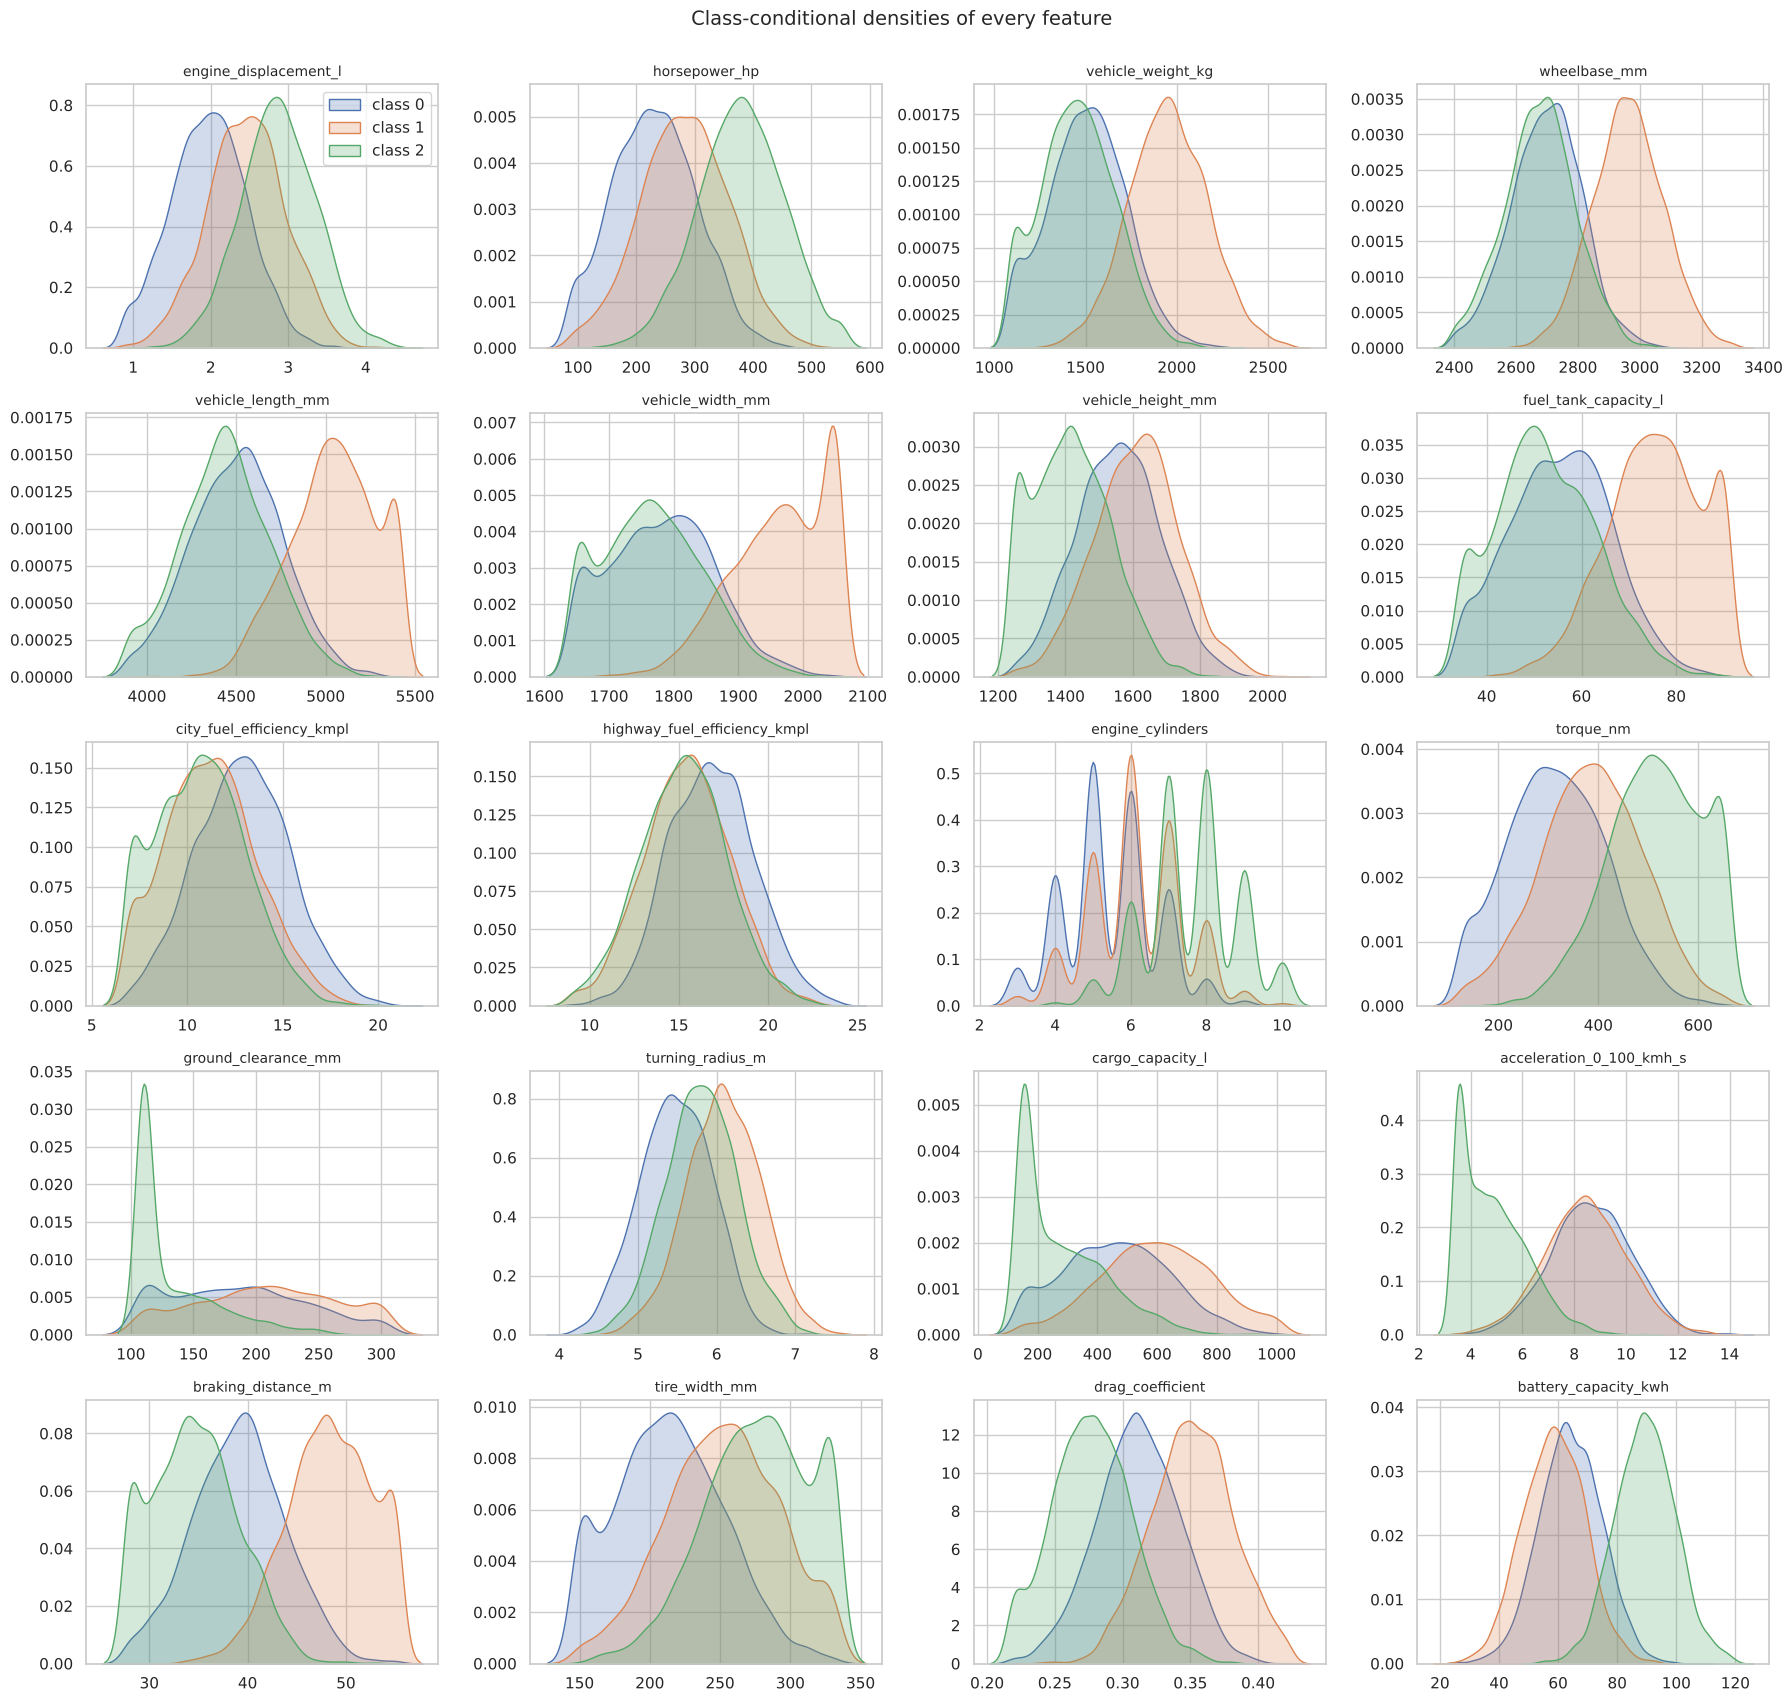

In [5]:
fig, axes = plt.subplots(5, 4, figsize=(18, 17))
for ax, c in zip(axes.ravel(), FEATURES):
    for k, col in zip([0,1,2], ['#4C72B0','#DD8452','#55A868']):
        sns.kdeplot(train.loc[train[TARGET]==k, c], ax=ax, fill=True, alpha=.25, color=col, label=f'class {k}', warn_singular=False)
    ax.set_title(c, fontsize=10); ax.set_xlabel(''); ax.set_ylabel('')
axes[0,0].legend(); plt.suptitle('Class-conditional densities of every feature', y=1.0, fontsize=14); plt.tight_layout(); plt.show()

In [6]:
display(train.groupby(TARGET)[FEATURES].mean().T.round(2).style.background_gradient(axis=1, cmap='coolwarm'))

vehicle_class,0,1,2
engine_displacement_l,1.970000,2.450000,2.870000
horsepower_hp,230.570000,282.250000,378.930000
vehicle_weight_kg,1503.650000,1950.930000,1454.890000
wheelbase_mm,2697.350000,2961.240000,2675.860000
vehicle_length_mm,4501.850000,5040.890000,4437.630000
vehicle_width_mm,1780.760000,1962.700000,1766.750000
vehicle_height_mm,1556.070000,1611.060000,1417.830000
fuel_tank_capacity_l,55.490000,75.440000,52.360000
city_fuel_efficiency_kmpl,12.880000,11.230000,10.690000
highway_fuel_efficiency_kmpl,16.840000,15.440000,15.250000


**Observations (class profiles):**
* **Class 2 = performance / sports-type:** highest hp, torque, cylinders, battery capacity, tyre width; **fastest 0–100 (≈4.9 s)**, shortest braking, lowest height, ground clearance and cargo, lowest drag coefficient.
* **Class 1 = large / SUV-type:** heaviest, longest, widest, longest wheelbase, largest fuel tank and cargo, highest ground clearance, longest braking distance, highest drag.
* **Class 0 = compact / economy-type:** smallest engine, best fuel efficiency, average dimensions.
* Class 0 sits **between** the other two on most axes, so most confusion should involve class 0 (confirmed later by the confusion matrices).
* The class-conditional densities are roughly **unimodal and Gaussian-shaped** with different means, which suggests a Gaussian Bayes classifier / LDA / logistic regression should work well.

### 2.4 Skewness, outliers and boundary clipping

,skew,min,n_at_min,max,n_at_max,n_unique,iqr_outliers
ground_clearance_mm,0.49,110.00,2302,300.00,328,191,0
cargo_capacity_l,0.33,150.00,1256,1000.00,64,802,0
acceleration_0_100_kmh_s,-0.09,3.50,709,14.00,3,884,0
vehicle_width_mm,0.24,1650.00,545,2050.00,612,401,0
city_fuel_efficiency_kmpl,0.22,7.00,411,20.87,1,1083,32
braking_distance_m,0.18,28.00,383,55.00,309,28,0
fuel_tank_capacity_l,0.18,35.00,346,90.00,358,56,0
vehicle_height_mm,0.09,1250.00,322,2050.00,1,663,10
vehicle_weight_kg,0.35,1100.00,291,2600.00,5,1271,17
tire_width_mm,-0.11,150.00,251,330.00,449,181,0


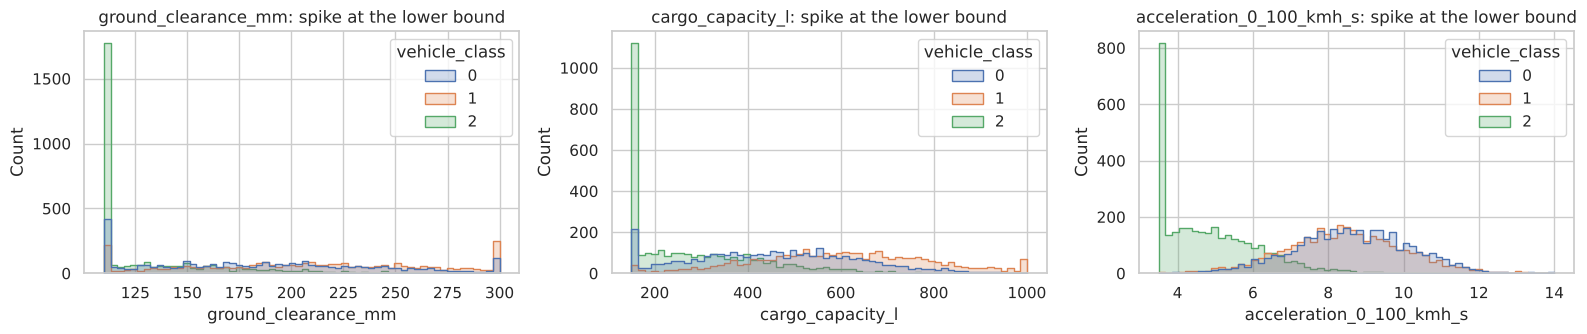

In [7]:
lo, hi = train[FEATURES].min(), train[FEATURES].max()
clip_df = pd.DataFrame({'skew': train[FEATURES].skew(), 'min': lo, 'n_at_min': (train[FEATURES]==lo).sum(),
                        'max': hi, 'n_at_max': (train[FEATURES]==hi).sum(), 'n_unique': train[FEATURES].nunique()})
q1, q3 = train[FEATURES].quantile(.25), train[FEATURES].quantile(.75); iqr = q3-q1
clip_df['iqr_outliers'] = ((train[FEATURES] < q1-1.5*iqr) | (train[FEATURES] > q3+1.5*iqr)).sum()
display(clip_df.round(2).sort_values('n_at_min', ascending=False))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
for a, c in zip(ax, ['ground_clearance_mm', 'cargo_capacity_l', 'acceleration_0_100_kmh_s']):
    sns.histplot(data=train, x=c, hue=TARGET, bins=60, ax=a, palette=['#4C72B0','#DD8452','#55A868'], element='step')
    a.set_title(f'{c}: spike at the lower bound')
plt.tight_layout(); plt.show()

**Observations:**
* All skewness values are small (|skew| < 0.5), so no log/power transforms are needed for model validity.
* Few IQR outliers, and they are physically plausible values, not errors. Since tree models are robust and linear models are scaled, we **do not remove outliers**: removing them would discard real information.
* Many features are **clipped at a hard floor or ceiling** (e.g. `ground_clearance_mm` = 110 for ~23% of rows, `cargo_capacity_l` = 150 for ~12.5%, `acceleration` = 3.5 s for ~7%). The data generator truncated values to a valid physical range. These spikes are dominated by one class (e.g. low clearance → class 2), so they carry signal. We test explicit "is-clipped" indicator features in Section 3.
* Discrete-valued features: `engine_cylinders` (8 values), `braking_distance_m` (28), `drag_coefficient` (21). These are ordinal numeric, so we keep them as numbers.

### 2.5 Correlations / multicollinearity

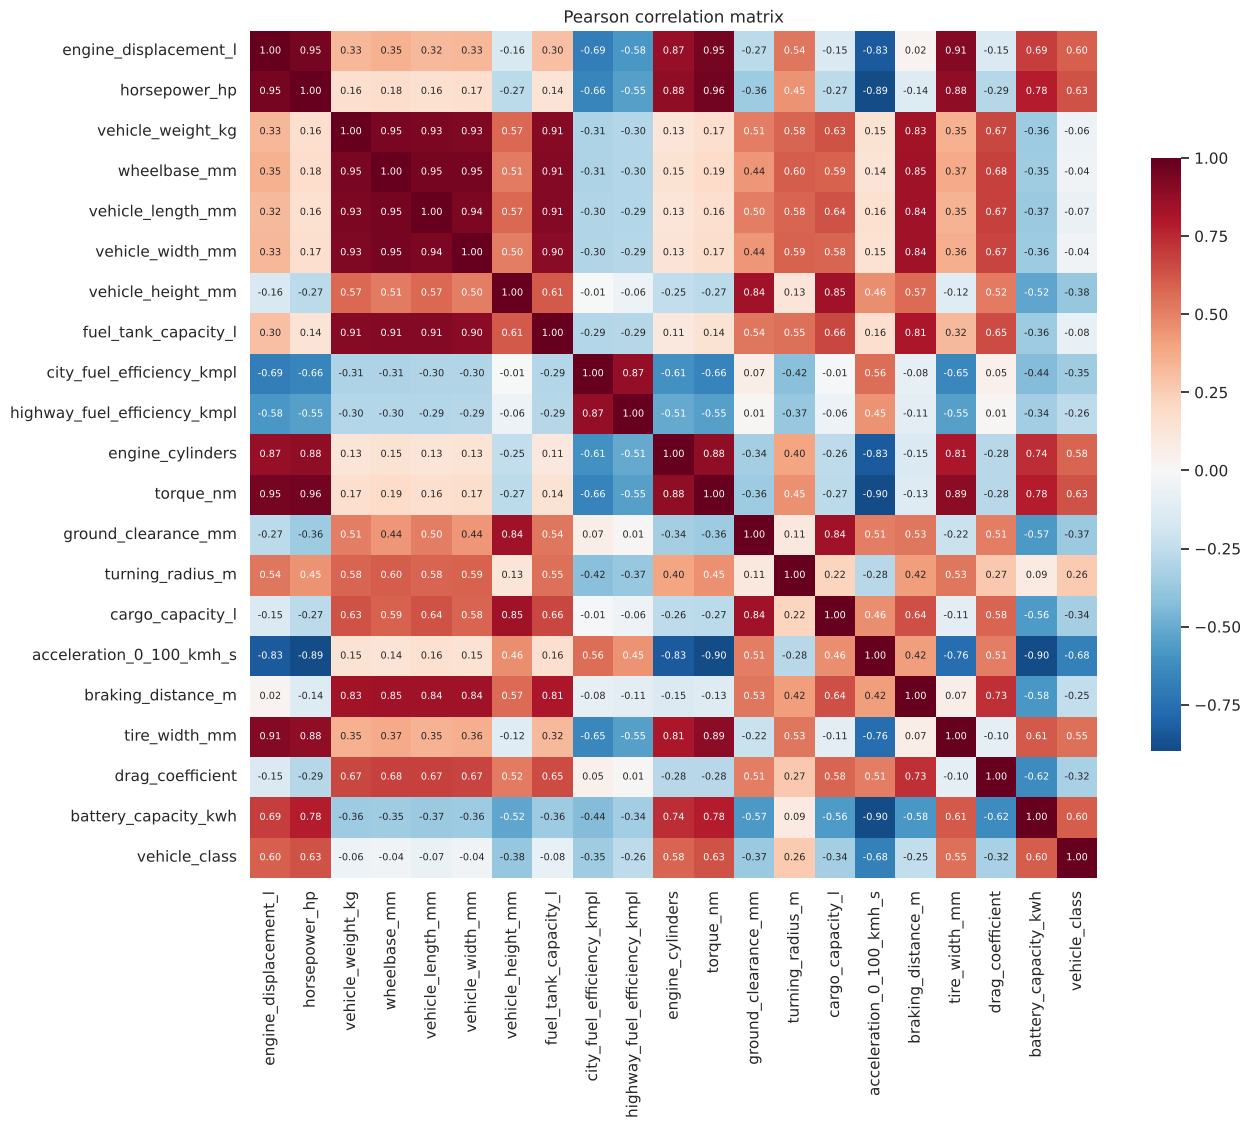

Feature pairs with |r| > 0.8: 34


r
horsepower_hp             torque_nm                     0.959
engine_displacement_l     torque_nm                     0.953
wheelbase_mm              vehicle_width_mm              0.952
engine_displacement_l     horsepower_hp                 0.950
wheelbase_mm              vehicle_length_mm             0.948
vehicle_weight_kg         wheelbase_mm                  0.945
vehicle_length_mm         vehicle_width_mm              0.937
vehicle_weight_kg         vehicle_length_mm             0.934
                          vehicle_width_mm              0.929
vehicle_length_mm         fuel_tank_capacity_l          0.914
engine_displacement_l     tire_width_mm                 0.912
wheelbase_mm              fuel_tank_capacity_l          0.912
vehicle_weight_kg         fuel_tank_capacity_l          0.906
vehicle_width_mm          fuel_tank_capacity_l          0.900
torque_nm                 acceleration_0_100_kmh_s     -0.897
acceleration_0_100_kmh_s  battery_capacity_kwh         -0.897
horsepower_hp             acceleration_0_100_kmh_s     -0.894
torque_nm                 tire_width_mm                 0.890
horsepower_hp             tire_width_mm                 0.884
                          engine_cylinders              0.882
engine_cylinders          torque_nm                     0.882
city_fuel_efficiency_kmpl highway_fuel_efficiency_kmpl  0.875
engine_displacement_l     engine_cylinders              0.873
wheelbase_mm              braking_distance_m            0.851

In [8]:
corr = train[FEATURES+[TARGET]].corr()
plt.figure(figsize=(14,11))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size':7}, square=True, cbar_kws={'shrink':.7})
plt.title('Pearson correlation matrix'); plt.show()
pairs = corr.loc[FEATURES, FEATURES].where(np.triu(np.ones((20,20)),1).astype(bool)).stack()
print('Feature pairs with |r| > 0.8:', (pairs.abs()>0.8).sum())
display(pairs[pairs.abs()>0.85].sort_values(key=abs, ascending=False).to_frame('r').round(3))

**Observations:**
* There is **strong multicollinearity**: two latent factors drive most features. One is *engine power* (displacement, hp, torque, cylinders, tyre width, battery, negatively 0–100 time); the other is *size* (length, wheelbase, width, weight, fuel tank).
* This **violates the Naive Bayes independence assumption**, so we expect Gaussian NB to underperform the full-covariance Bayes classifier. We test a decorrelation (PCA-whitening) fix.
* For logistic regression, collinearity inflates coefficient variance but does not hurt prediction much; L2 regularisation handles it.
* Note that the raw linear correlation with the target is weak for some features (e.g. weight), because class 1 is high and classes 0 and 2 are low. The relationship is **non-monotonic in the class index**, so the label must be treated as nominal (one-vs-rest / multinomial), not ordinal.

### 2.6 Feature relevance (mutual information & ANOVA F)

,mutual_info,anova_F,p_value
battery_capacity_kwh,0.4501,6239.3918,0.0
braking_distance_m,0.4499,6073.1469,0.0
acceleration_0_100_kmh_s,0.4035,5165.0367,0.0
wheelbase_mm,0.3896,4908.6511,0.0
vehicle_width_mm,0.3804,5068.2396,0.0
vehicle_length_mm,0.3611,4528.7514,0.0
vehicle_weight_kg,0.3572,4270.7444,0.0
drag_coefficient,0.3423,3754.2521,0.0
fuel_tank_capacity_l,0.3192,3690.0782,0.0
torque_nm,0.2613,2638.3815,0.0


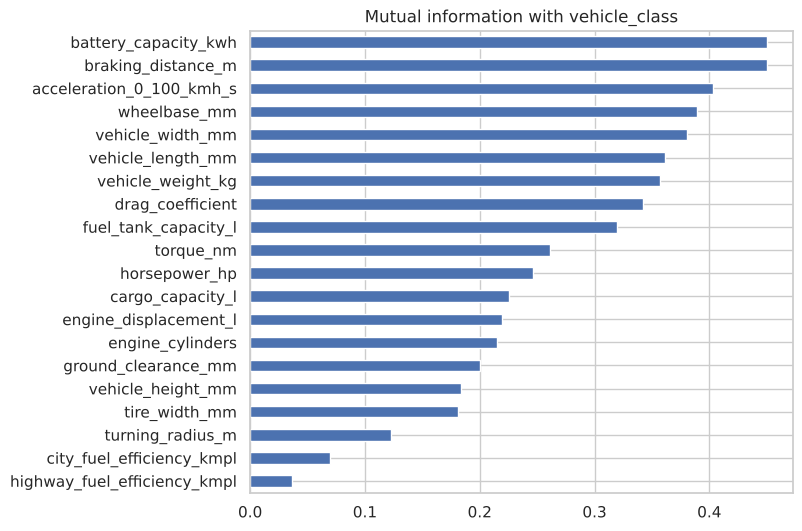

In [9]:
from sklearn.feature_selection import mutual_info_classif, f_classif
Xu = train.drop_duplicates(FEATURES)
mi = mutual_info_classif(Xu[FEATURES], Xu[TARGET], random_state=SEED)
F_, p_ = f_classif(Xu[FEATURES], Xu[TARGET])
rel = pd.DataFrame({'mutual_info': mi, 'anova_F': F_, 'p_value': p_}, index=FEATURES).sort_values('mutual_info', ascending=False)
display(rel.round(4))
rel['mutual_info'].plot.barh(figsize=(7,6), color='#4C72B0').invert_yaxis(); plt.title('Mutual information with vehicle_class'); plt.show()

**Observation:** `battery_capacity_kwh`, `braking_distance_m`, `acceleration_0_100_kmh_s` and the size features (wheelbase, width, length, weight) are the most informative. Fuel-efficiency features are the weakest individually. Every feature is still significant under ANOVA (p ≪ 0.05) and carries some signal, so **no feature is dropped**.

### 2.7 Low-dimensional view (PCA)

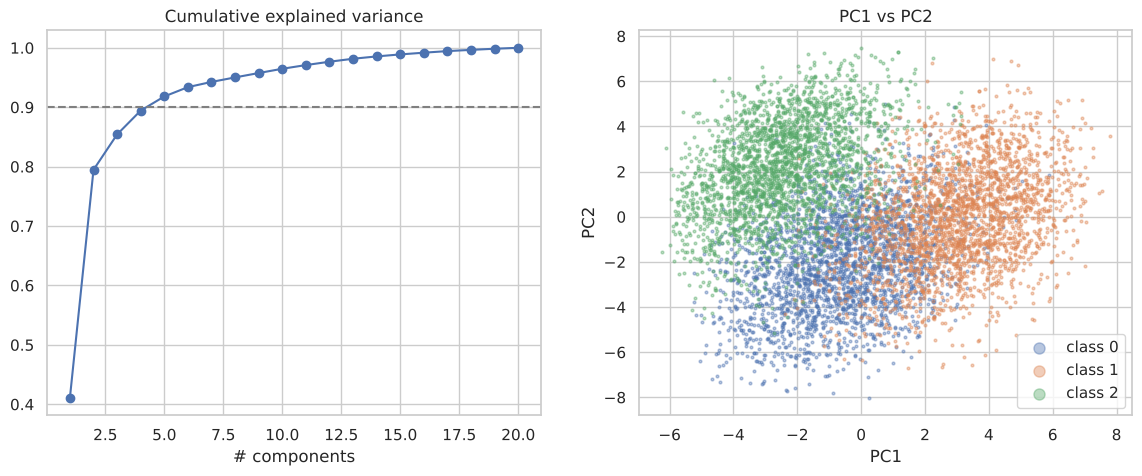

Variance explained by PC1, PC2: [0.411 0.384]


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
Z = StandardScaler().fit_transform(Xu[FEATURES]); pca = PCA().fit(Z); P = pca.transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(14,5))
ax[0].plot(np.arange(1,21), np.cumsum(pca.explained_variance_ratio_), marker='o'); ax[0].axhline(.9, ls='--', c='grey')
ax[0].set_title('Cumulative explained variance'); ax[0].set_xlabel('# components')
for k, col in zip([0,1,2], ['#4C72B0','#DD8452','#55A868']):
    m = Xu[TARGET].values==k; ax[1].scatter(P[m,0], P[m,1], s=4, alpha=.4, c=col, label=f'class {k}')
ax[1].legend(markerscale=4); ax[1].set_title('PC1 vs PC2'); ax[1].set_xlabel('PC1'); ax[1].set_ylabel('PC2'); plt.show()
print('Variance explained by PC1, PC2:', pca.explained_variance_ratio_[:2].round(3))

**Observation:** two principal components explain most of the variance, confirming the two latent factors (power, size). The classes form three clouds that are largely separable but **overlap at the boundaries, especially around class 0**. That overlap suggests irreducible noise, so we should not expect near-100% accuracy.

### 2.8 Train vs test distribution shift

In [11]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
ks = pd.DataFrame([(c, *stats.ks_2samp(Xu[c], test[c])) for c in FEATURES], columns=['feature','KS_stat','p_value']).set_index('feature')
display(ks.round(4).sort_values('KS_stat', ascending=False).head(8))
# adversarial validation: can a model tell train rows from test rows?
adv = pd.concat([Xu[FEATURES].assign(is_test=0), test[FEATURES].assign(is_test=1)])
auc = cross_val_score(RandomForestClassifier(200, n_jobs=-1, random_state=SEED), adv[FEATURES], adv['is_test'],
                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring='roc_auc').mean()
print(f'Adversarial-validation ROC-AUC = {auc:.3f}  (0.5 = indistinguishable)')
print('corr(vehicle_id, target) =', round(np.corrcoef(train[ID], train[TARGET])[0,1], 4))

,KS_stat,p_value
feature,,
ground_clearance_mm,0.0568,0.0000
cargo_capacity_l,0.0389,0.0067
city_fuel_efficiency_kmpl,0.0312,0.0514
engine_displacement_l,0.0277,0.1107
tire_width_mm,0.0263,0.1491
vehicle_length_mm,0.0237,0.2396
torque_nm,0.0232,0.2631
highway_fuel_efficiency_kmpl,0.0216,0.3434


Adversarial-validation ROC-AUC = 0.570  (0.5 = indistinguishable)
corr(vehicle_id, target) = 0.002


**Observations:**
* Most features show no significant shift. Only `ground_clearance_mm` and `cargo_capacity_l` (the two most heavily clipped features) differ slightly (KS statistic < 0.06). Adversarial validation AUC is about 0.57, close to 0.5, so the shift is **weak**: train and test come from essentially the same distribution, and local cross-validation is a reasonable proxy for the leaderboard.
* `vehicle_id` has no relationship with the target, so it is **dropped** as a feature and kept only for the submission file.

### EDA summary
| # | Finding | Consequence |
|---|---|---|
| 1 | No missing values, all numeric | No imputation or encoding needed |
| 2 | Balanced classes | Accuracy is fair; no resampling needed |
| 3 | 2,500 exact duplicate rows (ids 7501–10000) | **Deduplicate** before CV to avoid leakage |
| 4 | Clipped boundary values | Kept (informative); clip-indicator features tested |
| 5 | Strong multicollinearity (2 latent factors) | Hurts Naive Bayes; regularise LR; try decorrelation |
| 6 | Near-Gaussian, unimodal class-conditionals | Gaussian Bayes, LDA and LR should be strong |
| 7 | Class 0 lies between classes 1 and 2 | Most errors expected for class 0 |
| 8 | Only weak train/test shift (adv. AUC ≈ 0.57) | CV score is a reasonable proxy for the leaderboard |

## 3. Preprocessing

### 3.1 Effect of duplicates on cross-validation (justifies deduplication)

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, d in [('with duplicates (10,000 rows)', train), ('deduplicated (7,500 rows)', train.drop_duplicates(FEATURES))]:
    for mname, m in [('RandomForest', RandomForestClassifier(300, n_jobs=-1, random_state=SEED)),
                     ('LogisticRegression', make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)))]:
        rows.append((name, mname, cross_val_score(m, d[FEATURES], d[TARGET], cv=cv5).mean()))
display(pd.DataFrame(rows, columns=['data','model','CV accuracy']).pivot(index='model', columns='data', values='CV accuracy').round(4))

data,"deduplicated (7,500 rows)","with duplicates (10,000 rows)"
model,,
LogisticRegression,0.8941,0.8940
RandomForest,0.8825,0.9292


**Observation:** with duplicates, Random Forest's CV accuracy is inflated by ~4.7 points (88.3% → 92.9%) because it memorises the twin row, while logistic regression is barely affected. The duplicated estimate would wrongly rank RF above LR. **Decision: drop the 2,500 duplicates** and use the 7,500 unique rows for all CV and final training. Keeping them would also silently give those rows double weight.

### 3.2 Preprocessing pipeline
| Step | Applied to | Justification |
|---|---|---|
| Drop `vehicle_id` | all | identifier, no signal (corr ≈ 0) |
| Remove exact duplicates | train | prevents CV leakage / double weighting |
| Missing-value imputation | — | not needed (0 missing) |
| Encoding | — | all features already numeric |
| Outlier removal | — | not done: values are plausible and clipped by design; trees are robust |
| `StandardScaler` (inside the CV pipeline) | Logistic Regression | gradient solver convergence and fair L1/L2 penalties |
| `PCA` whitening (optional) | Naive Bayes variant | removes correlation so the independence assumption holds |
| Feature engineering (ratios, clip flags) | tested below | kept only if CV improves |

All scaling and transforms live **inside sklearn `Pipeline`s**, so they are refit on each training fold (no leakage into the validation fold).

In [13]:
df = train.drop_duplicates(FEATURES).reset_index(drop=True)
X, y = df[FEATURES].copy(), df[TARGET].values
X_test = test[FEATURES].copy()
print('Training rows after dedup:', X.shape, '| class counts:', np.bincount(y))

LO, HI = train[FEATURES].min(), train[FEATURES].max()
def add_features(d, ratios=True, clip_flags=True):
    d = d.copy()
    if ratios:
        d['power_to_weight']  = d.horsepower_hp / d.vehicle_weight_kg
        d['torque_to_weight'] = d.torque_nm / d.vehicle_weight_kg
        d['hp_per_litre']     = d.horsepower_hp / d.engine_displacement_l
        d['footprint_m2']     = d.vehicle_length_mm * d.vehicle_width_mm / 1e6
        d['volume_m3']        = d.footprint_m2 * d.vehicle_height_mm / 1e3
        d['height_to_width']  = d.vehicle_height_mm / d.vehicle_width_mm
        d['clear_to_height']  = d.ground_clearance_mm / d.vehicle_height_mm
        d['hwy_city_ratio']   = d.highway_fuel_efficiency_kmpl / d.city_fuel_efficiency_kmpl
        d['overhang_mm']      = d.vehicle_length_mm - d.wheelbase_mm
        d['density']          = d.vehicle_weight_kg / d.volume_m3
    if clip_flags:
        for c in FEATURES:
            if (train[c]==LO[c]).mean() > .02: d[c+'_at_min'] = (d[c] <= LO[c]).astype(int)
            if (train[c]==HI[c]).mean() > .02: d[c+'_at_max'] = (d[c] >= HI[c]).astype(int)
    return d

Training rows after dedup: (7500, 20) | class counts: [2539 2490 2471]


### 3.3 Feature-engineering experiment

In [14]:
from xgboost import XGBClassifier
fe_rows = []
for name, kw in [('raw 20 features', dict(ratios=False, clip_flags=False)), ('+ ratio features', dict(ratios=True, clip_flags=False)),
                 ('+ clip flags', dict(ratios=False, clip_flags=True)), ('+ both', dict(ratios=True, clip_flags=True))]:
    Xf = add_features(X, **kw)
    lr_s  = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), Xf, y, cv=cv5).mean()
    xgb_s = cross_val_score(XGBClassifier(n_estimators=400, learning_rate=.05, max_depth=4, subsample=.8, colsample_bytree=.8,
                                          n_jobs=-1, random_state=SEED, verbosity=0), Xf, y, cv=cv5).mean()
    fe_rows.append((name, Xf.shape[1], lr_s, xgb_s))
display(pd.DataFrame(fe_rows, columns=['feature set','# features','LogReg CV acc','XGBoost CV acc']).round(4))

,feature set,# features,LogReg CV acc,XGBoost CV acc
0,raw 20 features,20,0.8941,0.8847
1,+ ratio features,30,0.8948,0.8821
2,+ clip flags,38,0.8944,0.8841
3,+ both,48,0.8931,0.8833


**Observation / decision:** the engineered ratio and clip-indicator features **do not improve** either a linear or a boosted model; differences are within ±0.3%, smaller than the fold-to-fold standard deviation (~0.6%), so they are CV noise. The original features already contain the information, and the extra columns only add variance and collinearity. Following Occam's razor, **we keep the 20 original features** for all final models.

## 4. Model Experimentation
Protocol for every model:
* **5-fold stratified CV** on the 7,500 deduplicated rows (same folds for every model, so the comparison is fair).
* Hyper-parameters tuned with `GridSearchCV` / `RandomizedSearchCV` on accuracy.
* We record mean CV accuracy ± std and macro-F1 from out-of-fold predictions.
* The tuned model is refit on all 7,500 rows and its test predictions are saved as `submissions/<model>.csv`, so **every model can be submitted to Kaggle** and its public LB score recorded.

In [15]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from sklearn.base import clone

RESULTS, OOF, TEST_PROBA, FITTED = {}, {}, {}, {}

def evaluate(name, model, notes='', Xtr=None, Xte=None):
    # CV-evaluate a (tuned) model, refit on all data, save a submission
    Xtr = X if Xtr is None else Xtr; Xte = X_test if Xte is None else Xte
    t0 = time.time()
    proba = cross_val_predict(clone(model), Xtr, y, cv=cv5, method='predict_proba')
    pred = proba.argmax(1)
    fold_acc = [accuracy_score(y[v], pred[v]) for _, v in cv5.split(Xtr, y)]
    final = clone(model).fit(Xtr, y)
    tp = final.predict_proba(Xte)
    RESULTS[name] = dict(cv_accuracy=np.mean(fold_acc), cv_std=np.std(fold_acc), macro_f1=f1_score(y, pred, average='macro'),
                         train_accuracy=accuracy_score(y, final.predict(Xtr)), seconds=round(time.time()-t0, 1), notes=notes)
    OOF[name], TEST_PROBA[name], FITTED[name] = proba, tp, final
    fn = f"{OUT_DIR}/{name.replace(' ', '_').replace('(', '').replace(')', '').replace('+', 'plus')}.csv"
    pd.DataFrame({ID: test[ID], TARGET: tp.argmax(1)}).to_csv(fn, index=False)
    r = RESULTS[name]
    print(f"{name:40s} CV acc = {r['cv_accuracy']:.4f} ± {r['cv_std']:.4f} | macro-F1 = {r['macro_f1']:.4f} | train acc = {r['train_accuracy']:.4f} -> {fn}")
    return final

def show_search(gs, top=8):
    r = pd.DataFrame(gs.cv_results_).sort_values('rank_test_score')
    cols = [c for c in r.columns if c.startswith('param_')] + ['mean_test_score', 'std_test_score']
    display(r[cols].head(top).round(4)); print('Best params:', gs.best_params_, '| best CV acc:', round(gs.best_score_, 4))

### 4.1 Bayes Classifier (Gaussian class-conditional densities)
The Bayes-optimal rule is $\hat y = \arg\max_k \; P(y=k)\,p(\mathbf{x}\mid y=k)$. We model each class-conditional density as a **multivariate Gaussian with its own full covariance** $\Sigma_k$, estimated by MLE. The result is a quadratic decision boundary.

We implement it **from scratch** (for understanding and the viva), check it against sklearn's `QuadraticDiscriminantAnalysis`, and tune a shrinkage term $\Sigma_k \leftarrow (1-\lambda)\Sigma_k + \lambda I$ (in standardised units) for stability.

We also test the special case where all classes **share one covariance** $\Sigma$ (LDA), which makes the boundary linear.

In [16]:
from sklearn.base import BaseEstimator, ClassifierMixin
from scipy.special import logsumexp

class GaussianBayesClassifier(ClassifierMixin, BaseEstimator):
    # From-scratch Bayes classifier with Gaussian class-conditionals.
    # shared_cov=False -> each class has its own covariance (quadratic boundary, ~QDA)
    # shared_cov=True  -> pooled covariance (linear boundary, ~LDA)
    # reg: shrinkage of each covariance towards the identity (features are standardised internally)
    def __init__(self, reg=0.0, shared_cov=False):
        self.reg, self.shared_cov = reg, shared_cov
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y)
        self.mu_x_, self.sd_x_ = X.mean(0), X.std(0)
        Z = (X - self.mu_x_) / self.sd_x_
        self.classes_ = np.unique(y); d = Z.shape[1]
        self.log_prior_ = np.log(np.array([np.mean(y==k) for k in self.classes_]))
        self.means_ = np.array([Z[y==k].mean(0) for k in self.classes_])
        covs = [np.cov(Z[y==k], rowvar=False, bias=True) for k in self.classes_]
        if self.shared_cov:
            pooled = sum(np.mean(y==k)*S for k, S in zip(self.classes_, covs)); covs = [pooled]*len(self.classes_)
        covs = [(1-self.reg)*S + self.reg*np.eye(d) for S in covs]
        self.prec_ = [np.linalg.inv(S) for S in covs]
        self.logdet_ = [np.linalg.slogdet(S)[1] for S in covs]
        return self
    def _joint_log_likelihood(self, X):
        Z = (np.asarray(X, float) - self.mu_x_) / self.sd_x_
        out = []
        for k in range(len(self.classes_)):
            D = Z - self.means_[k]
            maha = np.einsum('ij,jk,ik->i', D, self.prec_[k], D)
            out.append(self.log_prior_[k] - 0.5*(self.logdet_[k] + maha))   # log P(k) + log N(x | mu_k, S_k) (+const)
        return np.column_stack(out)
    def predict_proba(self, X):
        J = self._joint_log_likelihood(X); return np.exp(J - logsumexp(J, axis=1, keepdims=True))
    def predict(self, X):
        return self.classes_[self._joint_log_likelihood(X).argmax(1)]

# sanity check vs sklearn QDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis, LinearDiscriminantAnalysis
ours = cross_val_score(GaussianBayesClassifier(reg=0.0), X, y, cv=cv5).mean()
skl  = cross_val_score(QuadraticDiscriminantAnalysis(), X, y, cv=cv5).mean()
print(f'From-scratch Gaussian Bayes (no reg): {ours:.4f} | sklearn QDA: {skl:.4f}')

gs_bayes = GridSearchCV(GaussianBayesClassifier(), {'reg': [0, 0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9], 'shared_cov': [False, True]},
                        cv=cv5, scoring='accuracy', n_jobs=-1).fit(X, y)
show_search(gs_bayes, 10)

From-scratch Gaussian Bayes (no reg): 0.8848 | sklearn QDA: 0.8848


,param_reg,param_shared_cov,mean_test_score,std_test_score
7,0.10,True,0.8932,0.0058
5,0.05,True,0.8929,0.0063
1,0.00,True,0.8924,0.0033
3,0.01,True,0.8921,0.0040
6,0.10,False,0.8895,0.0043
4,0.05,False,0.8888,0.0046
9,0.20,True,0.8887,0.0047
2,0.01,False,0.8867,0.0047
8,0.20,False,0.8864,0.0064
11,0.30,True,0.8853,0.0049


Best params: {'reg': 0.1, 'shared_cov': True} | best CV acc: 0.8932


Bayes Classifier (Gaussian, full cov)    CV acc = 0.8895 ± 0.0043 | macro-F1 = 0.8898 | train acc = 0.8921 -> submissions/Bayes_Classifier_Gaussian,_full_cov.csv
Bayes Classifier (shared cov = LDA)      CV acc = 0.8932 ± 0.0058 | macro-F1 = 0.8935 | train acc = 0.8929 -> submissions/Bayes_Classifier_shared_cov_=_LDA.csv


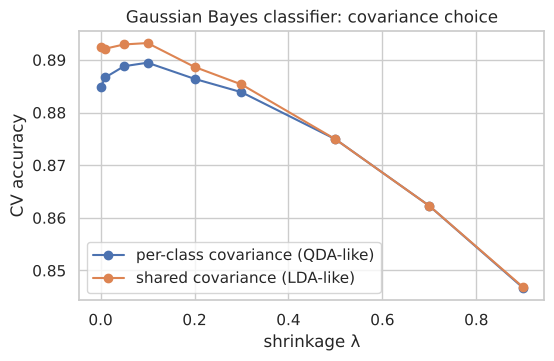

In [17]:
best_q = gs_bayes.cv_results_; df_b = pd.DataFrame(best_q)
bq = df_b[df_b.param_shared_cov==False].sort_values('rank_test_score').iloc[0]
bl = df_b[df_b.param_shared_cov==True].sort_values('rank_test_score').iloc[0]
evaluate('Bayes Classifier (Gaussian, full cov)', GaussianBayesClassifier(reg=bq.param_reg, shared_cov=False),
         notes=f'from-scratch, per-class covariance, shrinkage={bq.param_reg}')
evaluate('Bayes Classifier (shared cov = LDA)', GaussianBayesClassifier(reg=bl.param_reg, shared_cov=True),
         notes=f'pooled covariance -> linear boundary, shrinkage={bl.param_reg}')
plt.figure(figsize=(6,3.5))
for sc, lab in [(False, 'per-class covariance (QDA-like)'), (True, 'shared covariance (LDA-like)')]:
    s = df_b[df_b.param_shared_cov==sc].sort_values('param_reg'); plt.plot(s.param_reg.astype(float), s.mean_test_score, marker='o', label=lab)
plt.xlabel('shrinkage λ'); plt.ylabel('CV accuracy'); plt.legend(); plt.title('Gaussian Bayes classifier: covariance choice'); plt.show()

**Observations:**
* Our from-scratch implementation matches sklearn's QDA, which validates the derivation.
* The **shared-covariance (linear) version performs on par with or better than** the full per-class covariance version. The class covariances are similar enough that estimating three separate 20×20 matrices (630 parameters) adds variance without reducing bias.
* Mild shrinkage (λ = 0.1) helps the full-covariance model most (88.5% → 89.0%), since it has more parameters to estimate. Heavy shrinkage hurts, because it throws away the real correlation structure.
* The Gaussian generative assumption fits this data well (see EDA 2.3), so this simple model is already near the top of the table.

### 4.2 Naive Bayes
Gaussian Naive Bayes assumes the features are **conditionally independent** given the class: $p(\mathbf{x}\mid k)=\prod_j \mathcal N(x_j\mid\mu_{kj},\sigma^2_{kj})$.
Variants tested:
1. Plain Gaussian NB (tune `var_smoothing`).
2. NB after a **Yeo-Johnson power transform** (makes each marginal more Gaussian).
3. NB after **PCA whitening**, which decorrelates the features so the independence assumption is closer to true.
4. NB after **LDA projection** (2 discriminant components).

In [18]:
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import PowerTransformer
gs_nb = GridSearchCV(GaussianNB(), {'var_smoothing': np.logspace(-12, -1, 12)}, cv=cv5, scoring='accuracy', n_jobs=-1).fit(X, y)
show_search(gs_nb, 4)
nb_variants = {
    'plain GaussianNB': GaussianNB(var_smoothing=gs_nb.best_params_['var_smoothing']),
    'PowerTransform + GaussianNB': make_pipeline(PowerTransformer(), GaussianNB()),
    'Standardize + PCA-whiten + GaussianNB': make_pipeline(StandardScaler(), PCA(whiten=True), GaussianNB()),
    'LDA projection + GaussianNB': make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2), GaussianNB()),
}
nb_tab = pd.Series({k: cross_val_score(v, X, y, cv=cv5).mean() for k, v in nb_variants.items()}, name='CV accuracy').round(4)
display(nb_tab.to_frame())

,param_var_smoothing,mean_test_score,std_test_score
2,0.0,0.8475,0.0063
0,0.0,0.8473,0.0063
1,0.0,0.8473,0.0063
7,0.0,0.8471,0.0077


Best params: {'var_smoothing': np.float64(1e-10)} | best CV acc: 0.8475


,CV accuracy
plain GaussianNB,0.8475
PowerTransform + GaussianNB,0.8492
Standardize + PCA-whiten + GaussianNB,0.8581
LDA projection + GaussianNB,0.8924


In [19]:
evaluate('Naive Bayes (Gaussian)', nb_variants['plain GaussianNB'], notes=f"var_smoothing={gs_nb.best_params_['var_smoothing']:.0e}")
best_nb_var = nb_tab.drop('plain GaussianNB').idxmax()
evaluate('Naive Bayes (decorrelated)', nb_variants[best_nb_var], notes=best_nb_var)

Naive Bayes (Gaussian)                   CV acc = 0.8475 ± 0.0063 | macro-F1 = 0.8484 | train acc = 0.8472 -> submissions/Naive_Bayes_Gaussian.csv
Naive Bayes (decorrelated)               CV acc = 0.8924 ± 0.0040 | macro-F1 = 0.8926 | train acc = 0.8939 -> submissions/Naive_Bayes_decorrelated.csv


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lineardiscriminantanalysis', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['engine_displacement_l','horsepower_hp','vehicle_weight_kg',..., 'tire_width_mm','drag_coefficient','battery_capacity_kwh']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


**Observations:**
* Plain Gaussian NB is the **weakest model of all** (≈84.8%), about 4.5 points below the Bayes classifier with shared covariance. Strongly correlated features (r up to 0.96) are effectively counted several times, so the posteriors become over-confident and biased.
* The power transform barely helps (+0.2 points), because the marginals were already near-Gaussian; skew is not the problem, correlation is.
* PCA-whitening helps only a little (+1 point). It removes the *overall* correlation, but the features are still correlated *within each class*, which is what NB actually assumes away.
* **Projecting onto the 2 LDA directions first recovers the whole gap (89.2%).** In that space the class-conditional features are nearly independent. This confirms that the violated independence assumption, not the Gaussian assumption, is what hurts NB here.

### 4.3 Logistic Regression (multinomial / softmax)
Tuned: regularisation type (L1, L2, Elastic-Net) and strength `C`. Features are standardised inside the pipeline.
We also try **degree-2 polynomial features**, which give LR a quadratic boundary.

,param_logisticregression__C,param_logisticregression__penalty,param_logisticregression__l1_ratio,mean_test_score,std_test_score
4,0.1000,l2,NaN,0.8945,0.0058
29,1.0000,elasticnet,0.5,0.8945,0.0057
6,1.0000,l2,NaN,0.8943,0.0056
5,0.3162,l2,NaN,0.8943,0.0060
28,1.0000,elasticnet,0.2,0.8943,0.0056
30,1.0000,elasticnet,0.8,0.8941,0.0052
10,100.0000,l2,NaN,0.8940,0.0055
3,0.0316,l2,NaN,0.8940,0.0068


Best params: {'logisticregression__C': np.float64(0.1), 'logisticregression__penalty': 'l2'} | best CV acc: 0.8945


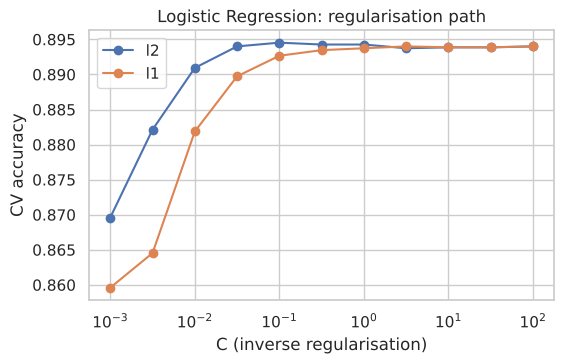

In [20]:
from sklearn.preprocessing import PolynomialFeatures
lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=10000, solver='saga', random_state=SEED))
lr_grid = [{'logisticregression__penalty': ['l2'], 'logisticregression__C': np.logspace(-3, 2, 11)},
           {'logisticregression__penalty': ['l1'], 'logisticregression__C': np.logspace(-3, 2, 11)},
           {'logisticregression__penalty': ['elasticnet'], 'logisticregression__C': [0.01, 0.1, 1, 10], 'logisticregression__l1_ratio': [0.2, 0.5, 0.8]}]
gs_lr = GridSearchCV(lr_pipe, lr_grid, cv=cv5, scoring='accuracy', n_jobs=-1).fit(X, y)
show_search(gs_lr, 8)
r = pd.DataFrame(gs_lr.cv_results_)
plt.figure(figsize=(6,3.5))
for pen in ['l2','l1']:
    s = r[r.param_logisticregression__penalty==pen].sort_values('param_logisticregression__C')
    plt.semilogx(s.param_logisticregression__C.astype(float), s.mean_test_score, marker='o', label=pen)
plt.xlabel('C (inverse regularisation)'); plt.ylabel('CV accuracy'); plt.legend(); plt.title('Logistic Regression: regularisation path'); plt.show()

Logistic Regression                      CV acc = 0.8945 ± 0.0058 | macro-F1 = 0.8948 | train acc = 0.8967 -> submissions/Logistic_Regression.csv


,param_logisticregression__C,mean_test_score,std_test_score
3,0.030,0.8911,0.0060
4,0.100,0.8895,0.0069
2,0.010,0.8893,0.0051
5,0.300,0.8876,0.0081
1,0.003,0.8853,0.0071
0,0.001,0.8804,0.0067


Best params: {'logisticregression__C': 0.03} | best CV acc: 0.8911


Logistic Regression (poly-2)             CV acc = 0.8911 ± 0.0060 | macro-F1 = 0.8918 | train acc = 0.8997 -> submissions/Logistic_Regression_poly-2.csv


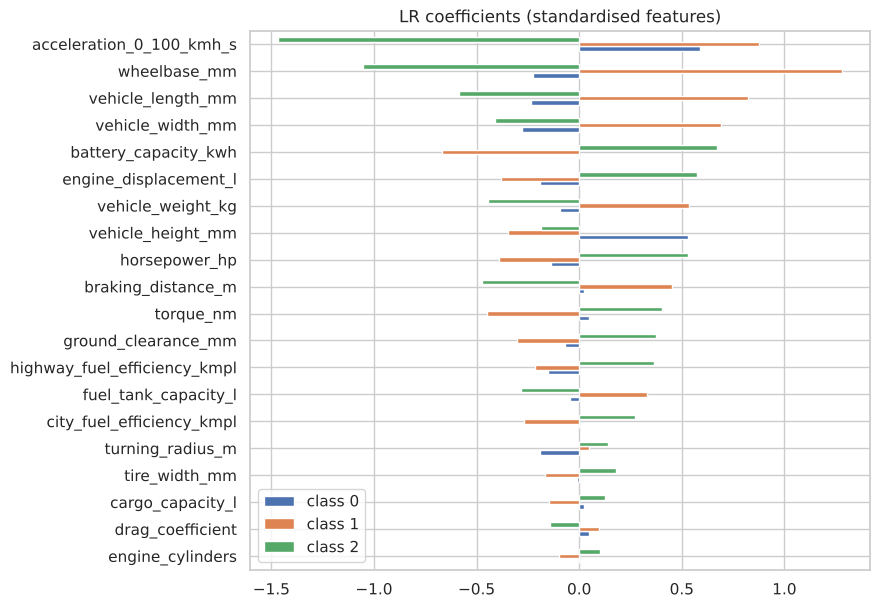

In [21]:
evaluate('Logistic Regression', gs_lr.best_estimator_, notes=str({k.split('__')[1]: v for k, v in gs_lr.best_params_.items()}))
gs_lrp = GridSearchCV(make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), StandardScaler(),
                                    LogisticRegression(max_iter=10000)),
                      {'logisticregression__C': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}, cv=cv5, scoring='accuracy', n_jobs=-1).fit(X, y)
show_search(gs_lrp, 6)
evaluate('Logistic Regression (poly-2)', gs_lrp.best_estimator_, notes=f"230 features, C={gs_lrp.best_params_['logisticregression__C']}")
coef = pd.DataFrame(FITTED['Logistic Regression'][-1].coef_.T, index=FEATURES, columns=['class 0','class 1','class 2'])
coef.loc[coef.abs().max(1).sort_values().index].plot.barh(figsize=(8,7)); plt.title('LR coefficients (standardised features)'); plt.show()

**Observations:**
* Logistic regression is one of the **best single models**. Accuracy is flat over a wide range of `C` and the penalty type hardly matters, which means the model is not over-fitting (train ≈ CV accuracy).
* Adding quadratic terms (230 features) does **not** help and needs strong regularisation. The optimal boundary is essentially **linear**, consistent with the LDA result in 4.1.
* The coefficients are interpretable. `acceleration_0_100` (fast = class 2), `wheelbase`/`length` (long = class 1), battery capacity and height are the dominant drivers. This matches the class profiles from EDA. Because of collinearity, individual coefficients should be read as a group (e.g. wheelbase and length share the "size" effect) rather than one at a time.

### 4.4 Decision Tree
Tuned: `criterion`, `max_depth`, `min_samples_leaf`, and cost-complexity pruning `ccp_alpha`.

,param_ccp_alpha,param_criterion,param_max_depth,param_min_samples_leaf,mean_test_score,std_test_score
222,0.0020,entropy,8,10,0.8639,0.0057
221,0.0020,entropy,8,5,0.8636,0.0041
125,0.0010,gini,6,1,0.8627,0.0040
220,0.0020,entropy,8,1,0.8627,0.0052
126,0.0010,gini,6,5,0.8625,0.0042
65,0.0005,gini,6,1,0.8624,0.0036
127,0.0010,gini,6,10,0.8624,0.0041
14,0.0000,gini,8,40,0.8623,0.0055


Best params: {'ccp_alpha': 0.002, 'criterion': 'entropy', 'max_depth': 8, 'min_samples_leaf': 10} | best CV acc: 0.8639


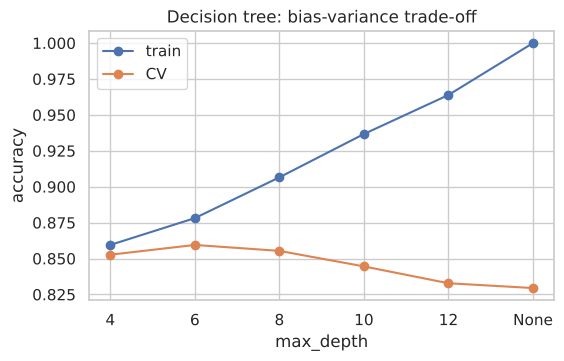

In [22]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
                     {'criterion': ['gini', 'entropy'], 'max_depth': [4, 6, 8, 10, 12, None],
                      'min_samples_leaf': [1, 5, 10, 20, 40], 'ccp_alpha': [0, 0.0005, 0.001, 0.002]},
                     cv=cv5, scoring='accuracy', n_jobs=-1).fit(X, y)
show_search(gs_dt, 8)
depth_curve = pd.DataFrame(gs_dt.cv_results_).query("param_criterion==@gs_dt.best_params_['criterion'] and param_ccp_alpha==0 and param_min_samples_leaf==1")
tr_acc = [accuracy_score(y, DecisionTreeClassifier(max_depth=d, criterion=gs_dt.best_params_['criterion'], random_state=SEED).fit(X, y).predict(X)) for d in [4,6,8,10,12,None]]
plt.figure(figsize=(6,3.5)); xs = ['4','6','8','10','12','None']
plt.plot(xs, tr_acc, marker='o', label='train'); plt.plot(xs, depth_curve.mean_test_score.values, marker='o', label='CV')
plt.xlabel('max_depth'); plt.ylabel('accuracy'); plt.legend(); plt.title('Decision tree: bias-variance trade-off'); plt.show()

Decision Tree                            CV acc = 0.8639 ± 0.0057 | macro-F1 = 0.8642 | train acc = 0.8764 -> submissions/Decision_Tree.csv


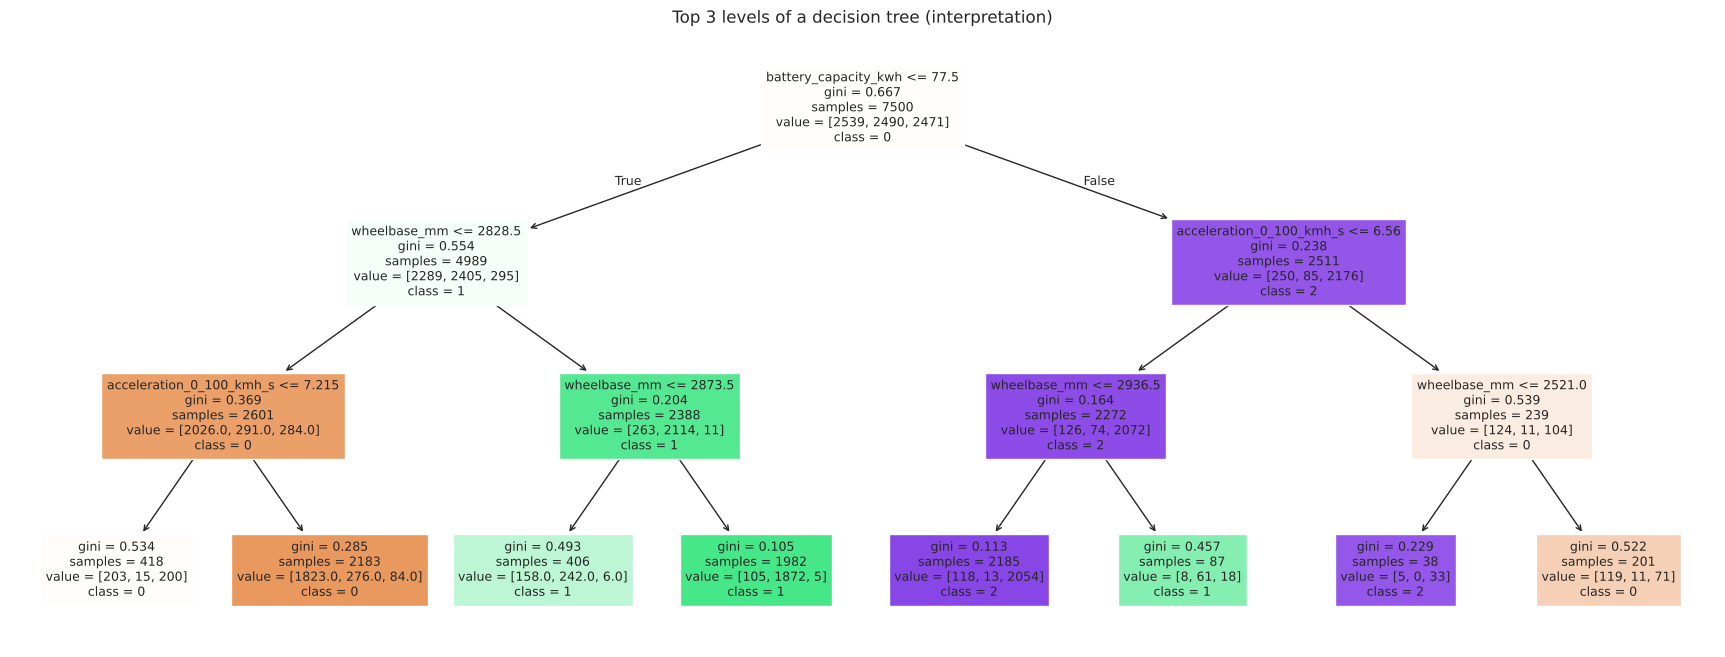

In [23]:
evaluate('Decision Tree', gs_dt.best_estimator_, notes=str(gs_dt.best_params_))
plt.figure(figsize=(22,8))
plot_tree(DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X, y), feature_names=FEATURES, class_names=['0','1','2'], filled=True, fontsize=9)
plt.title('Top 3 levels of a decision tree (interpretation)'); plt.show()

**Observations:**
* The single tree (86.4%) is the second-weakest model, ahead only of plain Naive Bayes. An unpruned tree reaches 100% train accuracy but much lower CV accuracy (classic high variance), and pruning via depth, leaf size and ccp_alpha recovers several points.
* Axis-aligned splits approximate the true *oblique* (linear-combination) boundary with a staircase, which needs many splits. This explains the gap to LR and LDA.
* The top splits are human-readable rules matching the EDA class profiles: `battery_capacity_kwh > 77.5` and `acceleration < 6.6 s` → class 2 (performance), otherwise `wheelbase > 2830 mm` → class 1 (large), else class 0.

### 4.5 Random Forest
Bagging plus random feature subsets reduces the tree's variance. Tuned with `RandomizedSearchCV`.

,param_n_estimators,param_min_samples_leaf,param_max_features,param_max_depth,param_criterion,mean_test_score,std_test_score
7,300,2,log2,16,entropy,0.8869,0.0029
17,300,2,sqrt,20,entropy,0.8855,0.0039
12,500,1,log2,20,entropy,0.8848,0.0041
3,500,1,0.7,None,entropy,0.8848,0.0062
20,300,1,sqrt,20,gini,0.8841,0.0050
23,300,8,log2,None,entropy,0.8839,0.0050
2,500,8,0.5,16,entropy,0.8839,0.0061
9,500,8,log2,20,entropy,0.8837,0.0065


Best params: {'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 16, 'criterion': 'entropy'} | best CV acc: 0.8869


Random Forest                            CV acc = 0.8869 ± 0.0029 | macro-F1 = 0.8874 | train acc = 0.9932 -> submissions/Random_Forest.csv


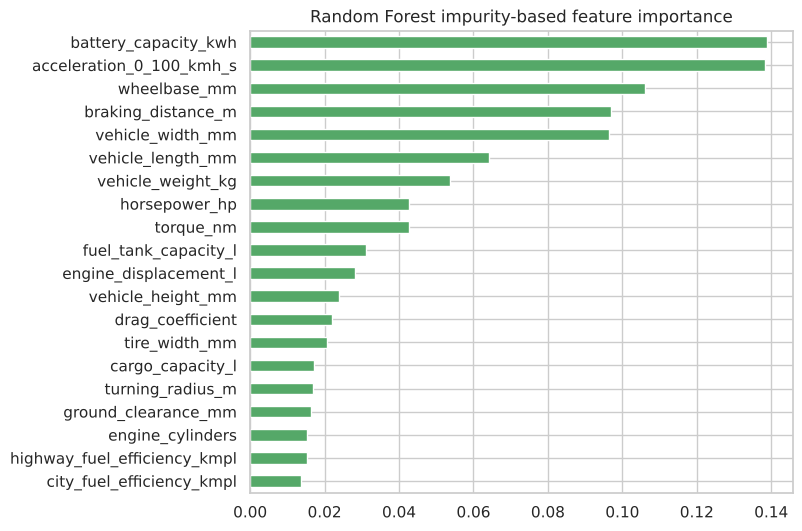

In [24]:
gs_rf = RandomizedSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1),
                           {'n_estimators': [300, 500, 800], 'max_features': ['sqrt', 'log2', 0.5, 0.7, 1.0],
                            'max_depth': [None, 12, 16, 20], 'min_samples_leaf': [1, 2, 4, 8], 'criterion': ['gini', 'entropy']},
                           n_iter=25, cv=cv5, scoring='accuracy', random_state=SEED, n_jobs=1).fit(X, y)
show_search(gs_rf, 8)
rf_best = evaluate('Random Forest', gs_rf.best_estimator_, notes=str(gs_rf.best_params_))
imp = pd.Series(rf_best.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(7,6), color='#55A868'); plt.title('Random Forest impurity-based feature importance'); plt.show()

**Observations:**
* Random Forest improves substantially over the single tree (86.4% → 88.7%, variance reduction through bagging), but it still trails the linear models.
* It reaches 99.3% train accuracy against 88.7% CV, the largest over-fitting gap of all models. Trees approximate a smooth oblique boundary only with a staircase, and the forest partly memorises the label noise in the overlap region.
* Feature importances agree with the mutual-information ranking: battery capacity, acceleration, wheelbase, braking distance and width come out on top.

### 4.6 XGBoost
Gradient-boosted trees with shrinkage and regularisation. Tuned with `RandomizedSearchCV`. Shallow trees (low `max_depth`) are expected to suit a near-linear boundary.

,param_colsample_bytree,param_gamma,param_learning_rate,param_max_depth,param_min_child_weight,param_n_estimators,param_reg_alpha,param_reg_lambda,param_subsample,mean_test_score,std_test_score
31,0.6221,0.0309,0.1614,1,5,806,3.6678,9.1791,0.7178,0.8881,0.0047
21,0.4542,1.6706,0.0261,6,3,859,0.0161,0.3212,0.8845,0.8879,0.0030
37,0.5820,1.0742,0.0266,5,5,302,0.0021,0.1315,0.8125,0.8876,0.0033
10,0.9558,1.3022,0.1550,1,8,979,0.0167,0.1400,0.7244,0.8875,0.0068
39,0.6601,1.4881,0.0212,2,5,1029,1.2367,3.9945,0.7636,0.8872,0.0072
29,0.6359,1.7841,0.0662,2,5,997,0.2433,3.4611,0.9457,0.8872,0.0072
28,0.7898,1.6984,0.0717,1,3,669,0.0096,0.3643,0.9892,0.8868,0.0059
14,0.9657,1.1977,0.0802,4,2,881,0.9755,2.8674,0.9486,0.8867,0.0029


Best params: {'colsample_bytree': np.float64(0.6220952201532667), 'gamma': np.float64(0.030913233057734857), 'learning_rate': np.float64(0.1613504925344338), 'max_depth': 1, 'min_child_weight': 5, 'n_estimators': 806, 'reg_alpha': np.float64(3.6677640620245797), 'reg_lambda': np.float64(9.179105123112295), 'subsample': np.float64(0.7177795568278342)} | best CV acc: 0.8881


XGBoost                                  CV acc = 0.8881 ± 0.0047 | macro-F1 = 0.8885 | train acc = 0.9049 -> submissions/XGBoost.csv


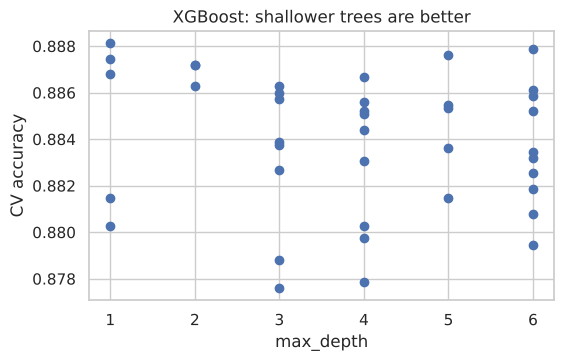

In [25]:
from scipy.stats import uniform, randint, loguniform
gs_xgb = RandomizedSearchCV(XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', tree_method='hist', random_state=SEED, n_jobs=-1, verbosity=0),
                            {'n_estimators': randint(200, 1200), 'learning_rate': loguniform(0.01, 0.2), 'max_depth': randint(1, 7),
                             'min_child_weight': randint(1, 10), 'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.4, 0.6),
                             'reg_lambda': loguniform(0.1, 20), 'reg_alpha': loguniform(1e-3, 5), 'gamma': uniform(0, 2)},
                            n_iter=40, cv=cv5, scoring='accuracy', random_state=SEED, n_jobs=1).fit(X, y)
show_search(gs_xgb, 8)
xgb_best = evaluate('XGBoost', gs_xgb.best_estimator_, notes=str({k: (round(v, 4) if isinstance(v, float) else v) for k, v in gs_xgb.best_params_.items()}))
r = pd.DataFrame(gs_xgb.cv_results_); plt.figure(figsize=(6,3.5))
plt.scatter(r.param_max_depth.astype(int), r.mean_test_score); plt.xlabel('max_depth'); plt.ylabel('CV accuracy'); plt.title('XGBoost: shallower trees are better'); plt.show()

**Observations:**
* XGBoost (88.8%) edges out Random Forest. The best configuration uses **depth-1 stumps** with strong L1/L2 regularisation. Boosted stumps form an *additive model* (a sum of per-feature functions), close to a generalised linear model. This is again consistent with the near-linear Bayes boundary.
* Once regularised, depth matters little: the top configurations span depth 1–6 within 0.15%. Boosting cannot beat the linear models here because there is no non-linear structure left to exploit.

### 4.7 CatBoost
Ordered boosting on symmetric (oblivious) trees, which is strongly regularised by design. Tuned over depth, learning rate, L2 regularisation and iterations.

In [26]:
from catboost import CatBoostClassifier
cb_base = CatBoostClassifier(loss_function='MultiClass', random_seed=SEED, verbose=0, thread_count=-1)
gs_cb = RandomizedSearchCV(cb_base, {'depth': [2, 3, 4, 5, 6], 'learning_rate': [0.02, 0.03, 0.05, 0.08], 'iterations': [500, 800, 1200],
                                     'l2_leaf_reg': [1, 3, 5, 10, 20], 'random_strength': [0.5, 1, 2], 'bagging_temperature': [0, 0.5, 1]},
                           n_iter=20, cv=cv5, scoring='accuracy', random_state=SEED, n_jobs=1).fit(X, y)
show_search(gs_cb, 8)
cb_best = evaluate('CatBoost', gs_cb.best_estimator_, notes=str(gs_cb.best_params_))

,param_random_strength,param_learning_rate,param_l2_leaf_reg,param_iterations,param_depth,param_bagging_temperature,mean_test_score,std_test_score
15,0.5,0.03,3,800,5,0.5,0.8891,0.0063
7,2.0,0.02,10,1200,3,0.5,0.8888,0.0064
19,2.0,0.05,10,1200,4,1.0,0.8888,0.0066
17,0.5,0.03,3,1200,3,0.5,0.8872,0.0060
11,1.0,0.08,1,1200,2,0.0,0.8869,0.0063
13,1.0,0.02,20,500,6,0.0,0.8869,0.0047
4,0.5,0.05,3,500,6,0.5,0.8868,0.0053
8,0.5,0.05,5,1200,3,0.0,0.8867,0.0041


Best params: {'random_strength': 0.5, 'learning_rate': 0.03, 'l2_leaf_reg': 3, 'iterations': 800, 'depth': 5, 'bagging_temperature': 0.5} | best CV acc: 0.8891


CatBoost                                 CV acc = 0.8891 ± 0.0063 | macro-F1 = 0.8894 | train acc = 0.9207 -> submissions/CatBoost.csv


**Observations:**
* CatBoost (88.9%) is the strongest tree-based model, but only marginally ahead of XGBoost and Random Forest; the three are within CV noise of each other. Its symmetric trees regularise much better than RF (train/CV gap 3 points vs 11).
* It still trails logistic regression by ~0.5 points. The extra flexibility of boosting buys nothing here because the true boundary is close to linear.

### 4.8 Ensembles of the course models
Different model families make partly different errors, so averaging their predicted probabilities can reduce variance.
* **Soft voting:** average the probabilities of the strongest diverse models (LR, LDA-Bayes, CatBoost, XGBoost).
* **Stacking:** a logistic-regression meta-learner trained on out-of-fold probabilities of the base models.

In [27]:
from sklearn.ensemble import VotingClassifier, StackingClassifier
base = [('lr', FITTED['Logistic Regression']), ('lda', FITTED['Bayes Classifier (shared cov = LDA)']),
        ('cb', FITTED['CatBoost']), ('xgb', FITTED['XGBoost'])]
evaluate('Soft Voting (LR+LDA+CatBoost+XGB)', VotingClassifier([(n, clone(m)) for n, m in base], voting='soft', n_jobs=1),
         notes='equal-weight probability averaging')
evaluate('Stacking (meta = LogReg)', StackingClassifier([(n, clone(m)) for n, m in base],
         final_estimator=LogisticRegression(max_iter=5000, C=1.0), cv=StratifiedKFold(5, shuffle=True, random_state=SEED+1), stack_method='predict_proba', n_jobs=1),
         notes='LR meta-learner on out-of-fold probabilities')

Soft Voting (LR+LDA+CatBoost+XGB)        CV acc = 0.8927 ± 0.0063 | macro-F1 = 0.8930 | train acc = 0.9047 -> submissions/Soft_Voting_LRplusLDAplusCatBoostplusXGB.csv


Stacking (meta = LogReg)                 CV acc = 0.8945 ± 0.0066 | macro-F1 = 0.8949 | train acc = 0.8937 -> submissions/Stacking_meta_=_LogReg.csv


,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('lr', ...), ('lda', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=5000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",StratifiedKFo... shuffle=True)
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](3,)","[0,1,2]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[Pipeline(step...ver='saga'))]), GaussianBayes...ared_cov=True), CatBoostClass....5, verbose=0), XGBClassifier...ree=None, ...)]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theu

## 5. Results and Discussion

,cv_accuracy,cv_std,macro_f1,train_accuracy,overfit_gap,seconds,notes,public_LB_score
Logistic Regression,0.8945,0.0058,0.8948,0.8967,0.0021,0.300000,"{'C': np.float64(0.1), 'penalty': 'l2'}",(fill after submitting)
Stacking (meta = LogReg),0.8945,0.0066,0.8949,0.8937,-0.0008,131.800000,LR meta-learner on out-of-fold probabilities,(fill after submitting)
Bayes Classifier (shared cov = LDA),0.8932,0.0058,0.8935,0.8929,-0.0003,0.100000,"pooled covariance -> linear boundary, shrinkage=0.1",(fill after submitting)
Soft Voting (LR+LDA+CatBoost+XGB),0.8927,0.0063,0.8930,0.9047,0.0120,24.300000,equal-weight probability averaging,(fill after submitting)
Naive Bayes (decorrelated),0.8924,0.0040,0.8926,0.8939,0.0015,0.100000,LDA projection + GaussianNB,(fill after submitting)
Logistic Regression (poly-2),0.8911,0.0060,0.8918,0.8997,0.0087,5.000000,"230 features, C=0.03",(fill after submitting)
"Bayes Classifier (Gaussian, full cov)",0.8895,0.0043,0.8898,0.8921,0.0027,0.100000,"from-scratch, per-class covariance, shrinkage=0.1",(fill after submitting)
CatBoost,0.8891,0.0063,0.8894,0.9207,0.0316,17.600000,"{'random_strength': 0.5, 'learning_rate': 0.03, 'l2_leaf_reg': 3, 'iterations': 800, 'depth': 5, 'bagging_temperature': 0.5}",(fill after submitting)
XGBoost,0.8881,0.0047,0.8885,0.9049,0.0168,5.500000,"{'colsample_bytree': np.float64(0.6221), 'gamma': np.float64(0.0309), 'learning_rate': np.float64(0.1614), 'max_depth': 1, 'min_child_weight': 5, 'n_estimators': 806, 'reg_alpha': np.float64(3.6678), 'reg_lambda': np.float64(9.1791), 'subsample': np.float64(0.7178)}",(fill after submitting)
Random Forest,0.8869,0.0029,0.8874,0.9932,0.1063,12.600000,"{'n_estimators': 300, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 16, 'criterion': 'entropy'}",(fill after submitting)


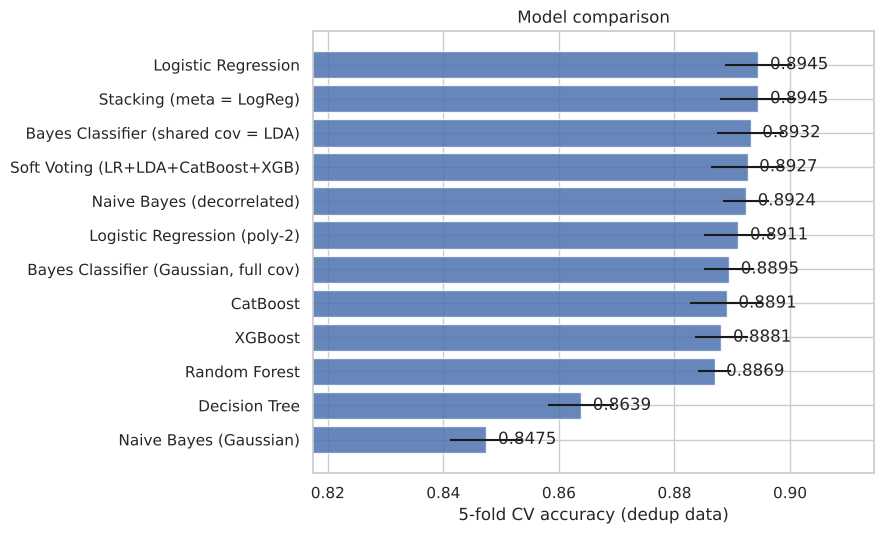

In [28]:
res = pd.DataFrame(RESULTS).T
res['overfit_gap'] = res['train_accuracy'] - res['cv_accuracy']
res = res.sort_values('cv_accuracy', ascending=False)
res['public_LB_score'] = '(fill after submitting)'
display(res[['cv_accuracy','cv_std','macro_f1','train_accuracy','overfit_gap','seconds','notes','public_LB_score']]
        .style.format({'cv_accuracy':'{:.4f}','cv_std':'{:.4f}','macro_f1':'{:.4f}','train_accuracy':'{:.4f}','overfit_gap':'{:.4f}'})
        .background_gradient(subset=['cv_accuracy'], cmap='Greens'))
res.to_csv('model_results.csv')
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(res.index[::-1], res.cv_accuracy[::-1], xerr=res.cv_std[::-1], color='#4C72B0', alpha=.85)
for i, v in enumerate(res.cv_accuracy[::-1]): ax.text(v+.002, i, f'{v:.4f}', va='center')
ax.set_xlim(res.cv_accuracy.min()-.03, res.cv_accuracy.max()+.02); ax.set_xlabel('5-fold CV accuracy (dedup data)'); ax.set_title('Model comparison'); plt.tight_layout(); plt.show()

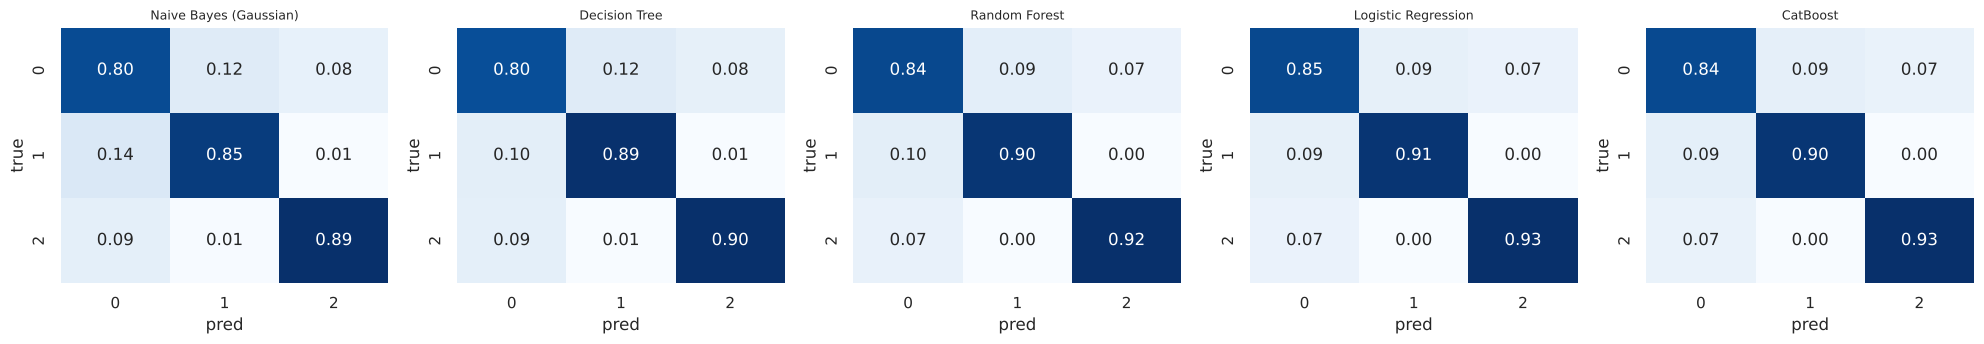

              precision    recall  f1-score   support

           0     0.8510    0.8456    0.8483      2539
           1     0.9071    0.9100    0.9086      2490
           2     0.9262    0.9292    0.9277      2471

    accuracy                         0.8945      7500
   macro avg     0.8948    0.8949    0.8948      7500
weighted avg     0.8944    0.8945    0.8945      7500



In [29]:
show = ['Naive Bayes (Gaussian)', 'Decision Tree', 'Random Forest', 'Logistic Regression', 'CatBoost', res.index[0]]
show = list(dict.fromkeys(show))
fig, axes = plt.subplots(1, len(show), figsize=(4*len(show), 3.6))
for a, n in zip(axes, show):
    cm = confusion_matrix(y, OOF[n].argmax(1), normalize='true')
    sns.heatmap(cm, annot=True, fmt='.2f', cmap='Blues', cbar=False, ax=a); a.set_title(n, fontsize=9); a.set_xlabel('pred'); a.set_ylabel('true')
plt.tight_layout(); plt.show()
print(classification_report(y, OOF[res.index[0]].argmax(1), digits=4))

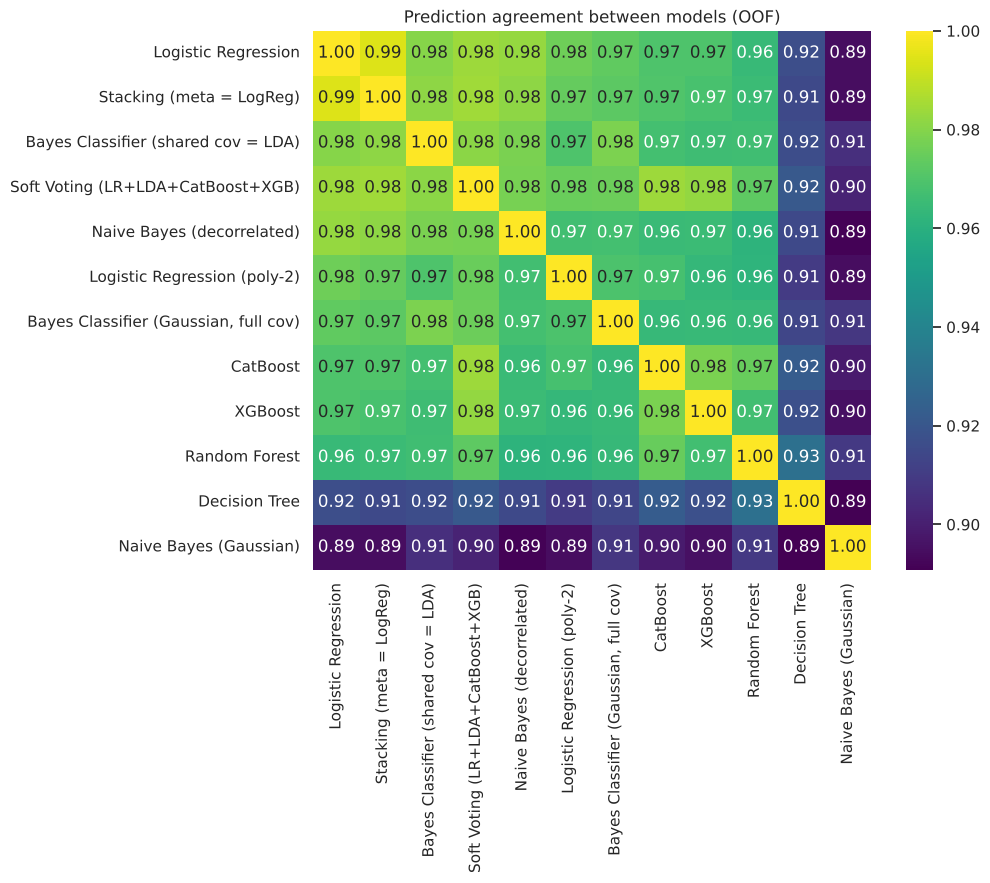

Rows misclassified by ALL models : 417 (5.6%)
Rows misclassified by NO model   : 5828 (77.7%)


In [30]:
# How similar are the models' errors? (agreement between OOF predictions)
names = list(res.index)
agree = pd.DataFrame([[np.mean(OOF[a].argmax(1)==OOF[b].argmax(1)) for b in names] for a in names], index=names, columns=names)
plt.figure(figsize=(9,7)); sns.heatmap(agree, annot=True, fmt='.2f', cmap='viridis'); plt.title('Prediction agreement between models (OOF)'); plt.show()
# Are errors concentrated on 'hard' rows that every model gets wrong?
wrong = np.column_stack([OOF[n].argmax(1)!=y for n in names]).sum(1)
print('Rows misclassified by ALL models :', (wrong==len(names)).sum(), f'({(wrong==len(names)).mean():.1%})')
print('Rows misclassified by NO model   :', (wrong==0).sum(), f'({(wrong==0).mean():.1%})')

### Discussion
1. **Linear decision boundaries win.** The Bayes classifier with shared covariance (= LDA) and logistic regression are both linear, and they match or beat every tree ensemble. The EDA explains why: near-Gaussian class-conditional densities with similar covariances. Under those conditions the Bayes-optimal boundary is (close to) linear.
2. **Model ranking follows the bias–variance trade-off.** Naive Bayes (high bias from a wrong independence assumption, 84.8%) < Decision Tree (high variance, 86.4%) < Random Forest ≈ XGBoost ≈ CatBoost ≈ full-covariance Bayes (88.7–89.0%) < LR-poly2 ≈ soft voting ≈ LDA ≈ decorrelated NB (89.1–89.3%) < Logistic Regression = Stacking (89.45%). The flexible models show large train–CV gaps (RF: 99.3% vs 88.7%) and are fitting noise.
3. **There is an accuracy ceiling near 89–90%.** 417 rows (5.6%) are misclassified by *every* model, and they sit in the class-overlap region (mainly class 0 vs the others). Logistic regression is also well calibrated (next cell): its errors match its own predicted uncertainty. Both point to irreducible (Bayes) error / label noise, not a modelling shortfall. Engineered features, splines, polynomial terms, deeper models and ensembles all failed to push past it.
4. **Class 0 (the "middle" class) causes most errors** (F1 0.85 vs 0.91/0.93). Class 1 vs class 2 are almost never confused, since they sit at opposite ends of the size/power axes.
5. **The data-leakage lesson.** Without removing the 2,500 duplicate rows, CV would have ranked Random Forest best (92.9%) when it is actually weaker on unseen data (88.7%). Correct validation design changed the model choice.
6. **Ensembling adds nothing measurable.** Stacking only ties LR, and soft voting is slightly lower, because the strong models make highly correlated errors, leaving little diversity to exploit. By Occam's razor we prefer the simpler LR.
7. **Leaderboard noise.** The public LB uses only part of the 2,500 test rows (~1,250 if split 50/50), so its standard error is ≈ √(0.89·0.11/1250) ≈ 0.9%. Public-LB differences under ~1.5–2 points between models are therefore **not** significant. That is why model selection is based on CV over 7,500 rows.

In [31]:
# Calibration check of the best model: do its errors match its own confidence? (evidence of a noise ceiling)
p = OOF['Logistic Regression']; conf = p.max(1); wrong = p.argmax(1) != y
bins = [0, .5, .7, .9, .99, 1.01]
cal = pd.DataFrame([(f'[{lo:.2f}, {hi:.2f})', ((conf>=lo)&(conf<hi)).sum(), wrong[(conf>=lo)&(conf<hi)].mean(), 1-conf[(conf>=lo)&(conf<hi)].mean())
                    for lo, hi in zip(bins[:-1], bins[1:])], columns=['confidence bin','n rows','observed error','expected error (1-conf)'])
display(cal.round(3))
print(f'Expected accuracy implied by the model\'s own probabilities: {conf.mean():.4f} | observed CV accuracy: {1-wrong.mean():.4f}')

,confidence bin,n rows,observed error,expected error (1-conf)
0,"[0.00, 0.50)",55,0.564,0.539
1,"[0.50, 0.70)",1017,0.366,0.397
2,"[0.70, 0.90)",1672,0.169,0.186
3,"[0.90, 0.99)",2750,0.035,0.041
4,"[0.99, 1.01)",2006,0.004,0.004


Expected accuracy implied by the model's own probabilities: 0.8847 | observed CV accuracy: 0.8945


**Observation:** observed error in each confidence bin closely tracks the model's own predicted error, so LR is well calibrated. About 30% of rows have confidence below 0.9, and that is where nearly all errors live. This is the class-overlap region where no classifier can be reliably right, so the ~89–90% ceiling reflects the data, not the model.

## 6. Best Model and Final Submission

In [32]:
best_name = res.index[0]
print('Best model by 5-fold CV accuracy:', best_name)
display(res.loc[[best_name], ['cv_accuracy','cv_std','macro_f1','notes']])
final_pred = TEST_PROBA[best_name].argmax(1)
submission = pd.DataFrame({ID: test[ID], TARGET: final_pred.astype(int)})
assert list(submission.columns) == list(sample_sub.columns) and len(submission) == len(sample_sub)
assert (submission[ID].values == sample_sub[ID].values).all() and set(submission[TARGET]) <= {0, 1, 2}
submission.to_csv('submission.csv', index=False)
print('submission.csv written | predicted class distribution:', np.bincount(final_pred))
print('\nAll per-model submission files (each can be uploaded to Kaggle to record its public LB score):')
for f in sorted(os.listdir(OUT_DIR)): print('  ', f)

Best model by 5-fold CV accuracy: Logistic Regression


,cv_accuracy,cv_std,macro_f1,notes
Logistic Regression,0.894533,0.005757,0.894846,"{'C': np.float64(0.1), 'penalty': 'l2'}"


submission.csv written | predicted class distribution: [835 833 832]

All per-model submission files (each can be uploaded to Kaggle to record its public LB score):
   Bayes_Classifier_Gaussian,_full_cov.csv
   Bayes_Classifier_shared_cov_=_LDA.csv
   CatBoost.csv
   Decision_Tree.csv
   Logistic_Regression.csv
   Logistic_Regression_poly-2.csv
   Naive_Bayes_Gaussian.csv
   Naive_Bayes_decorrelated.csv
   Random_Forest.csv
   Soft_Voting_LRplusLDAplusCatBoostplusXGB.csv
   Stacking_meta_=_LogReg.csv
   XGBoost.csv


**Final note.** Every model above has its own submission file in `submissions/`, so each one's public-leaderboard score can be recorded in the report table. The model with the highest public LB score must be named in the report (project statement §5). The private leaderboard is used for grading, train/test shift is weak, and public-LB noise is ≈ ±0.9%, so we rely on **CV accuracy** for the final model choice rather than chasing small public-LB differences.